# Support Vector Machine (SVM) Classification Pipeline
This notebook provides a complete, end-to-end pipeline for training, tuning, and evaluating a Support Vector Machine classifier using `scikit-learn` and `pandas`.

## 1. Import Required Libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 2. Load and Prepare the Dataset
We select the specific numeric and flag columns required for feature matrix `X` and properly clean/convert data types.

In [34]:
df = pd.read_csv("../Data/supermarket_subset.csv")

feature_columns = [
    'customer_visit_frequency',
    'average_monthly_visits',
    'customer_tenure_months',
    'days_since_last_purchase',
    'average_transaction_value',
    'loyalty_program_member',
    'selling_price',
    'discount_percent',
    'promotion_active',
    'shopping_period'
]

target_column = 'repeat_purchase'

X = pd.get_dummies(df[feature_columns], drop_first=True)

for col in ['selling_price', 'discount_percent']:
    if col in X.columns:
        X[col] = X[col].astype(int)

valid_rows = X.dropna().index
X = X.loc[valid_rows]
y = df.loc[valid_rows, target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (9600, 13)
Testing set shape: (2400, 13)


## 3. Build Pipeline & Hyperparameter Tuning
SVMs require feature scaling (`StandardScaler`) to perform well. Placing it inside a `Pipeline` prevents data leakage during cross-validation.

In [35]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(class_weight='balanced', random_state=RANDOM_STATE))
])

param_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale', 0.1]
    }
]

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

print("Training and tuning SVM model...")
grid_search.fit(X_train, y_train)

print("\nBest Parameters Found:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Training and tuning SVM model...
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Best Parameters Found:
  svm__C: 0.1
  svm__gamma: scale
  svm__kernel: rbf


## 4. Evaluate Model Performance

Classification Report:
              precision    recall  f1-score   support

          No       0.43      0.45      0.44       975
         Yes       0.61      0.59      0.60      1425

    accuracy                           0.53      2400
   macro avg       0.52      0.52      0.52      2400
weighted avg       0.53      0.53      0.53      2400



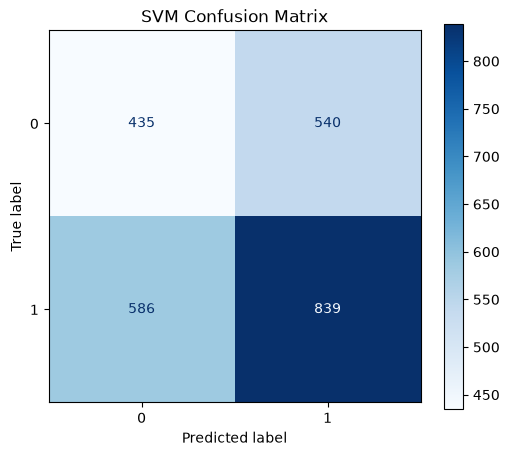

In [36]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
plt.title("SVM Confusion Matrix")
plt.grid(False)
plt.show()